# Social Media Use and Mental Health: Correlation and Prediction

**Question:** Is the way people use social media related to how they feel? And can social media habits alone
tell us who is likely to feel depressed often?

**This notebook looks at two things:**
1. **Correlation:** how daily social media time and habits (comparing yourself to others, getting distracted, etc.)
   relate to self-reported depression, worry, sleep problems and concentration.
2. **Prediction:** whether a simple model can predict who reports feeling depressed often, using only social media habits and basic demographics.

**Dataset:**
"Social Media and Mental Health" survey on Kaggle (Souvik Ahmed, 2022), 481 responses collected with an online form: https://www.kaggle.com/datasets/souvikahmed071/social-media-and-mental-health
Mental health items are self-rated on a 1 to 5 scale.

I first wanted to use the Public Health Agency of Canada's 2018 HBSC study on Canadian adolescents
(https://www.canada.ca/en/public-health/services/publications/science-research-data/mental-health-problematic-social-media-use-canadian-adolescents.html),
but that page is only a report with summary results. The respondent-level data isn't downloadable, so I used this public survey instead.

**Steps taken**
1. Load the survey
2. Clean it: shorten column names, remove non-users, fix free-text gender, turn time ranges into numbers
3. Explore: who answered and how much time they spend on social media
4. Correlation: which habits go together with worse mental health
5. Prediction: build a baseline and a logistic regression model, and compare them
6. Which features matter most
7. Findings, limitations and next steps

**Note:** this is survey data from people who chose to answer, so everything here is correlation, not causation.

## 1. Load the data

The file is small (481 rows, 21 columns), so I load all of it.

In [ ]:
# logistics
import numpy as np                # maths on whole columns at once
import pandas as pd               # tables aka dataframes
import matplotlib.pyplot as plt   # charts
import seaborn as sns             # nicer statistical charts built on top of matplotlib
from scipy import stats           # for spearman correlation with p-values

# scikit-learn = the standard python library for machine learning
from sklearn.model_selection import train_test_split, cross_val_score   # splitting data + cross-validation
from sklearn.preprocessing import StandardScaler    # rescales numbers to mean 0, sd 1
from sklearn.pipeline import make_pipeline          # chains "scale, then fit model" into 1 step
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, ConfusionMatrixDisplay

import os
os.makedirs("figures", exist_ok=True)   # make sure the output folder exists (exist_ok=True: no error if it already does)

RANDOM_STATE = 42   # fixes the "randomness" so i get the same split and same results every re-run

raw = pd.read_csv("data/smmh.csv")
print(f"{len(raw)} rows, {raw.shape[1]} columns")

481 rows, 21 columns


In [2]:
# the original column names are the full survey questions -- way too long to type
raw.columns.tolist()

['Timestamp',
 '1. What is your age?',
 '2. Gender',
 '3. Relationship Status',
 '4. Occupation Status',
 '5. What type of organizations are you affiliated with?',
 '6. Do you use social media?',
 '7. What social media platforms do you commonly use?',
 '8. What is the average time you spend on social media every day?',
 '9. How often do you find yourself using Social media without a specific purpose?',
 '10. How often do you get distracted by Social media when you are busy doing something?',
 "11. Do you feel restless if you haven't used Social media in a while?",
 '12. On a scale of 1 to 5, how easily distracted are you?',
 '13. On a scale of 1 to 5, how much are you bothered by worries?',
 '14. Do you find it difficult to concentrate on things?',
 '15. On a scale of 1-5, how often do you compare yourself to other successful people through the use of social media?',
 '16. Following the previous question, how do you feel about these comparisons, generally speaking?',
 '17. How often do

## 2. Clean the data

**Problem I found:** the column names are whole questions (e.g. *"9. How often do you find yourself using Social media without a specific purpose?"*).

**What I did:** rename them to short names. The ones I use most:

| Short name | Survey question (shortened) | Answer |
|---|---|---|
| `daily_time` | Average time on social media every day | time range, e.g. "Between 2 and 3 hours" |
| `purposeless_use` | Using social media without a specific purpose | 1 (never) to 5 (very often) |
| `distracted_by_sm` | Getting distracted by social media when busy | 1 to 5 |
| `restless_without_sm` | Feeling restless without social media | 1 to 5 |
| `compare_to_others` | Comparing yourself to successful people on social media | 1 to 5 |
| `seek_validation` | Seeking validation (likes, comments) on social media | 1 to 5 |
| `depressed` | How often do you feel depressed or down? | 1 to 5 |
| `worries` / `sleep_issues` / `difficulty_concentrating` | Other mental health questions | 1 to 5 |

In [3]:
df = raw.copy()   # work on a copy so the raw data stays untouched
df.columns = [
    "timestamp", "age", "gender", "relationship", "occupation", "organization",
    "uses_social_media", "platforms", "daily_time",
    "purposeless_use", "distracted_by_sm", "restless_without_sm", "easily_distracted",
    "worries", "difficulty_concentrating", "compare_to_others", "comparison_feeling",
    "seek_validation", "depressed", "interest_fluctuation", "sleep_issues",
]
df.head()

,timestamp,age,gender,relationship,occupation,organization,uses_social_media,platforms,daily_time,purposeless_use,...,restless_without_sm,easily_distracted,worries,difficulty_concentrating,compare_to_others,comparison_feeling,seek_validation,depressed,interest_fluctuation,sleep_issues
0,4/18/2022 19:18:47,21.0,Male,In a relationship,University Student,University,Yes,"Facebook, Twitter, Instagram, YouTube, Discord...",Between 2 and 3 hours,5,...,2,5,2,5,2,3,2,5,4,5
1,4/18/2022 19:19:28,21.0,Female,Single,University Student,University,Yes,"Facebook, Twitter, Instagram, YouTube, Discord...",More than 5 hours,4,...,2,4,5,4,5,1,1,5,4,5
2,4/18/2022 19:25:59,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram, YouTube, Pinterest",Between 3 and 4 hours,3,...,1,2,5,4,3,3,1,4,2,5
3,4/18/2022 19:29:43,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram",More than 5 hours,4,...,1,3,5,3,5,1,2,4,3,2
4,4/18/2022 19:33:31,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram, YouTube",Between 2 and 3 hours,3,...,4,4,5,5,3,3,3,4,4,1


**Problem I found:** a few more things needed fixing before analysis:
- 3 people said they **don't use social media**, so the rest of the questions don't apply to them.
- **Gender was a free-text box**, so there are 9 different answers (e.g. "Nonbinary", "Non-binary", "NB" all mean the same thing).
- **Daily time is text** ("Between 2 and 3 hours"), which a model can't use directly.
- `organization` is the only column with **missing values**, and I don't need it.

**What I did**: remove the non-users, group gender into Male / Female / Other, turn the time ranges into 0-5 (in order), count how many platforms each person uses, and drop the columns I don't need.

In [4]:
# check for missing values: only show columns that have some
df.isna().sum()[df.isna().sum() > 0]

organization    30
dtype: int64

In [5]:
# remove people who don't use social media
print(df["uses_social_media"].value_counts())
df = df[df["uses_social_media"] == "Yes"].copy()

# gender: keep Male / Female, put everything else in "Other"
    # .where(condition, other) keeps the value if condition is True, otherwise replaces it with "Other"
print(df["gender"].value_counts())
df["gender"] = df["gender"].where(df["gender"].isin(["Male", "Female"]), "Other")

# time ranges are in order, so map them to numbers 0-5 (a model needs numbers, not text)
time_order = {
    "Less than an Hour": 0,
    "Between 1 and 2 hours": 1,
    "Between 2 and 3 hours": 2,
    "Between 3 and 4 hours": 3,
    "Between 4 and 5 hours": 4,
    "More than 5 hours": 5,
}
df["daily_time_level"] = df["daily_time"].map(time_order)

# count platforms: "Facebook, Instagram, YouTube" --> split at commas --> 3 items
df["num_platforms"] = df["platforms"].str.split(",").apply(len)

# drop columns i don't need
df = df.drop(columns=["timestamp", "uses_social_media", "organization"])
print(f"after cleaning: {len(df)} rows")

uses_social_media
Yes    478
No       3
Name: count, dtype: int64
gender
Female                 263
Male                   208
Nonbinary                1
Non-binary               1
NB                       1
unsure                   1
Trans                    1
Non binary               1
There are others???      1
Name: count, dtype: int64
after cleaning: 478 rows


## 3. Explore: who answered, and how much do they use social media?

In [ ]:
# the big 4: mean, standard deviation, min/max and quartiles
df[["age", "daily_time_level", "num_platforms", "depressed", "worries", "sleep_issues"]].describe().round(2)

,age,daily_time_level,num_platforms,depressed,worries,sleep_issues
count,478.00,478.00,478.00,478.00,478.00,478.00
mean,26.10,2.92,4.28,3.27,3.57,3.21
std,9.88,1.58,1.97,1.31,1.28,1.46
min,13.00,0.00,1.00,1.00,1.00,1.00
25%,21.00,2.00,3.00,2.00,3.00,2.00
50%,22.00,3.00,4.00,3.00,4.00,3.00
75%,26.00,4.00,6.00,4.00,5.00,5.00
max,91.00,5.00,9.00,5.00,5.00,5.00


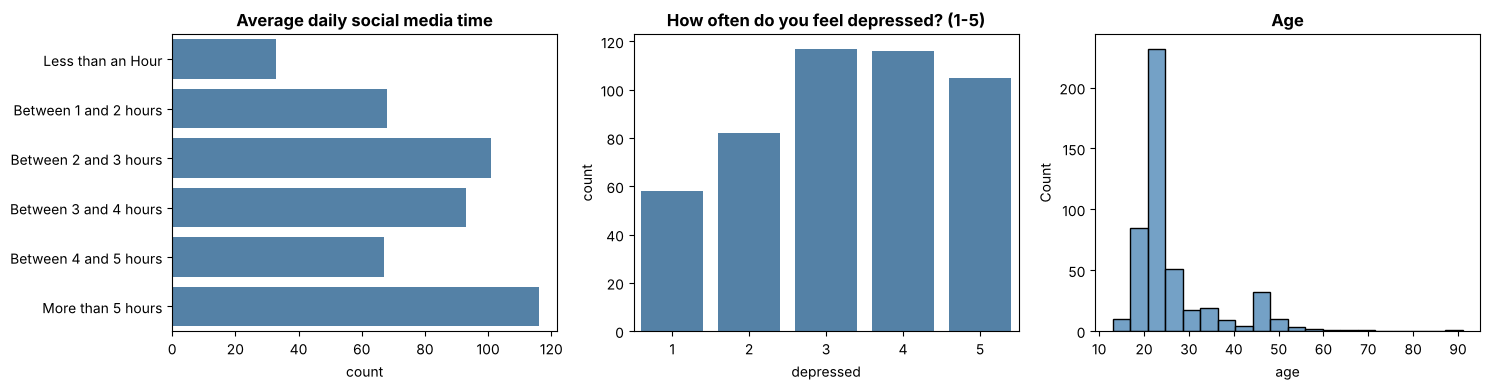

In [7]:
# three charts side by side
    # fig = the whole image, axes = the 3 drawing areas inside it
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# chart 1: daily time, in order from least to most
order = list(time_order.keys())
sns.countplot(data=df, y="daily_time", order=order, ax=axes[0], color="steelblue")
axes[0].set_title("Average daily social media time", weight="bold")
axes[0].set_ylabel("")

# chart 2: depression score
sns.countplot(data=df, x="depressed", ax=axes[1], color="steelblue")
axes[1].set_title("How often do you feel depressed? (1-5)", weight="bold")

# chart 3: age
sns.histplot(df["age"], bins=20, ax=axes[2], color="steelblue")
axes[2].set_title("Age", weight="bold")

plt.tight_layout()   # stop labels from getting cut off in the saved image
plt.savefig("figures/eda_distributions.png", dpi=150)   # dpi for sharpness
plt.show()

Most people who answered are university students in their early 20s, and more than half spend over 3 hours a day on social media.

A few people are much older (up to 91), but there aren't many of them, so the sample doesn't represent the general population.

In [8]:
# average depression score for each daily time group
    # groupby = "for each time group", agg = calculate the mean and the count of people
summary = df.groupby("daily_time_level")["depressed"].agg(["mean", "count"]).round(2)
summary.index = order   # show the time ranges instead of 0-5
summary

,mean,count
Less than an Hour,2.03,33
Between 1 and 2 hours,2.84,68
Between 2 and 3 hours,3.18,101
Between 3 and 4 hours,3.37,93
Between 4 and 5 hours,3.45,67
More than 5 hours,3.77,116


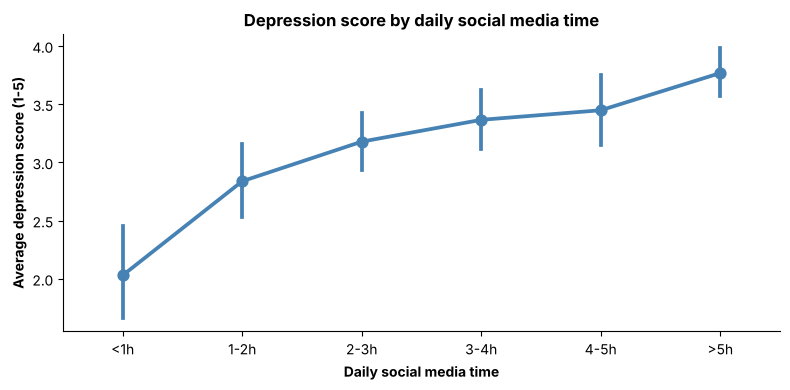

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))

# pointplot: one dot = average depression score for that time group
    # the vertical lines are 95% CI: shorter = more certain about that average
sns.pointplot(data=df, x="daily_time_level", y="depressed", errorbar=("ci", 95), color="steelblue", ax=ax)

ax.set_xticks(range(6))
ax.set_xticklabels(["<1h", "1-2h", "2-3h", "3-4h", "4-5h", ">5h"])
ax.set_xlabel("Daily social media time", weight="bold")
ax.set_ylabel("Average depression score (1-5)", weight="bold")
ax.set_title("Depression score by daily social media time", weight="bold")
ax.spines[["top", "right"]].set_visible(False)   # for a cleaner look

plt.tight_layout()
plt.savefig("figures/depression_by_time.png", dpi=150)
plt.show()

## 4. Correlation: which habits go together with worse mental health?

**Problem I found:** the answers are on 1-5 scales, not real measurements. The gap between "2" and "3" isn't
necessarily the same as between "4" and "5". Pearson correlation assumes evenly spaced numbers.

**What I did**: use **Spearman** correlation instead. 
It ranks the values first so it only asks "when one goes up, does the other tend to go up too?".

How to read it: from -1 to 1. 0 = no relationship, around 0.3 = moderate, 0.5+ = strong. Positive = both go up together.

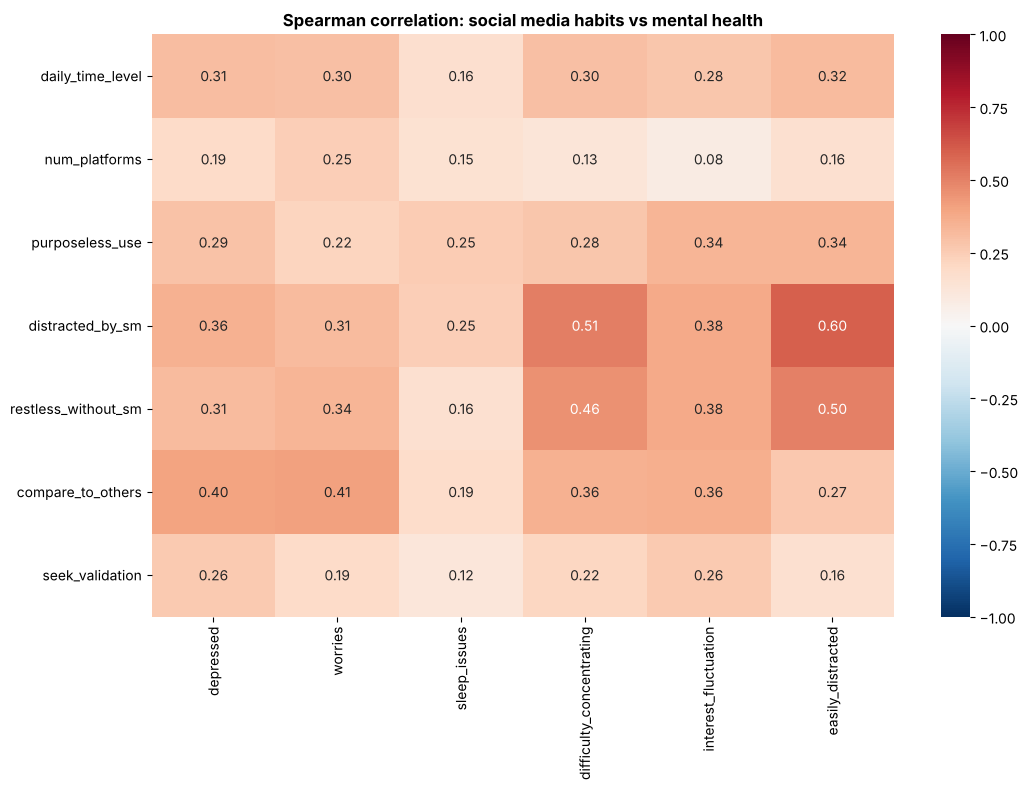

In [ ]:
# rows of the heatmap: social media habits
usage_cols = ["daily_time_level", "num_platforms", "purposeless_use", "distracted_by_sm",
              "restless_without_sm", "compare_to_others", "seek_validation"]

# columns of the heatmap: mental health questions
mh_cols = ["depressed", "worries", "sleep_issues", "difficulty_concentrating",
           "interest_fluctuation", "easily_distracted"]

corr = df[usage_cols + mh_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 8))

# only show habits vs mental health (not every pair)
    # annot=True writes the number in each box, fmt=".2f" = 2 decimals
    # cmap="RdBu_r": red = positive (move together), blue = negative (move oppposite), vmin/vmax fix the colour scale at -1 to 1
sns.heatmap(corr.loc[usage_cols, mh_cols], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation: social media habits vs mental health", weight="bold")

plt.tight_layout()
plt.savefig("figures/correlation_heatmap.png", dpi=150)
plt.show()

In [11]:
# daily time vs each mental health question, with p-values
    # p-value = how likely we'd see a correlation this big if there was really no relationship. small = unlikely to be chance
rows = []
for col in mh_cols:
    rho, p = stats.spearmanr(df["daily_time_level"], df[col])
    rows.append({"mental health question": col, "spearman_rho": round(rho, 3), "p_value": p})

pd.DataFrame(rows).sort_values("spearman_rho", ascending=False)

,mental health question,spearman_rho,p_value
5,easily_distracted,0.319,9.031885e-13
0,depressed,0.310,4.523242e-12
1,worries,0.300,2.092498e-11
3,difficulty_concentrating,0.298,3.170608e-11
4,interest_fluctuation,0.280,4.660207e-10
2,sleep_issues,0.165,3.011889e-04


**What I see**
- More time on social media goes together with worse answers on **every** mental health question, but only moderately (around 0.3; sleep is weaker at about 0.17).
- All p-values are below 0.001, so these are very unlikely to be due to chance.
- For depression, **how** people use social media matters more than **how long**: comparing yourself to others (0.40)
  and getting distracted by social media (0.36) are stronger than daily time (0.31).

## 5. Prediction: can social media habits predict who feels depressed often?

**What I'm predicting:** `high_depression` = 1 if someone answered 4 or 5 to "how often do you feel depressed", otherwise 0.

**Problem I found:** the survey has other mental health questions (worries, sleep, concentration...). They're answered at the same time and are basically symptoms of the same thing. If I give them to the model, it would look really accurate, but it wouldn't tell me anything about social media. This is called **data leakage**.

**What I did:** only use social media habits + basic demographics (age, gender, occupation) as inputs.

In [ ]:
# 1 if depression score is 4 or 5, otherwise 0
df["high_depression"] = (df["depressed"] >= 4).astype(int)

# how balanced are the two groups?
print(df["high_depression"].value_counts(normalize=True).round(3))

# baseline: if i just guessed "not high" (0) for everyone, how often would i be right?
    # any real model has to beat this, otherwise it's useless
baseline_acc = (df["high_depression"] == 0).mean()
print(f"baseline accuracy (always guess 0): {baseline_acc:.3f}")

high_depression
0    0.538
1    0.462
Name: proportion, dtype: float64
baseline accuracy (always guess 0): 0.538


The two groups are about 46% / 54%, so they're roughly balanced. Guessing "not high" for everyone would already be right 54% of the time,
so that's the number to beat.

In [13]:
# inputs: social media habits + demographics (no other mental health questions -- see data leakage above)
feature_cols = ["age", "daily_time_level", "num_platforms", "purposeless_use", "distracted_by_sm",
                "restless_without_sm", "compare_to_others", "comparison_feeling", "seek_validation",
                "gender", "occupation"]

# models need numbers, so turn text columns into 0/1 columns
    # e.g. gender --> gender_Male (1 or 0) and gender_Other (1 or 0). Female is when both are 0
    # drop_first=True removes one column per group since it's already implied by the others
X = pd.get_dummies(df[feature_cols], columns=["gender", "occupation"], drop_first=True, dtype=int)
y = df["high_depression"]
X.head()

,age,daily_time_level,num_platforms,purposeless_use,distracted_by_sm,restless_without_sm,compare_to_others,comparison_feeling,seek_validation,gender_Male,gender_Other,occupation_Salaried Worker,occupation_School Student,occupation_University Student
0,21.0,2,6,5,3,2,2,3,2,1,0,0,0,1
1,21.0,5,6,4,3,2,5,1,1,0,0,0,0,1
2,21.0,3,4,3,2,1,3,3,1,0,0,0,0,1
3,21.0,5,2,4,2,1,5,1,2,0,0,0,0,1
4,21.0,2,3,3,5,4,3,3,3,0,0,0,0,1


In [14]:
# keep 20% of people aside as a test set: the models never see them during training
    # stratify=y keeps the same 46/54 split in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"training set: {len(X_train)} people, test set: {len(X_test)} people")

training set: 382 people, test set: 96 people


### The model: Logistic regression

Logistic regression is the yes/no version of the regression from class: it gives each person a probability of being in the "high" group.

**Problem I found:** the inputs are on different scales (age goes up to 91, the habit questions only go to 5),
which makes the coefficients hard to compare.

**What I did**: scale every input to mean 0 and standard deviation 1 first. `make_pipeline` makes sure the scaling is only learned from the training data.

To check the model I use **5-fold cross-validation**: split the training set into 5 parts, train on 4 and test on the 5th, 5 times. This is more reliable than testing on one split only.

In [15]:
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))   # max_iter: give it enough steps to finish fitting

# cross-validation: 5 scores, one per fold
cv_acc = cross_val_score(log_reg, X_train, y_train, cv=5, scoring="accuracy")
cv_auc = cross_val_score(log_reg, X_train, y_train, cv=5, scoring="roc_auc")
print("accuracy per fold:", cv_acc.round(3), "--> mean", round(cv_acc.mean(), 3))
print("ROC AUC per fold: ", cv_auc.round(3), "--> mean", round(cv_auc.mean(), 3))

accuracy per fold: [0.649 0.792 0.632 0.618 0.724] --> mean 0.683
ROC AUC per fold:  [0.727 0.828 0.739 0.753 0.753] --> mean 0.76


### Comparing with the baseline

| Column | What it means |
|---|---|
| `cv_accuracy` | % of people the model put in the right group (average of the 5 folds) |
| `cv_roc_auc` | How well the model ranks people from most to least likely to be "high". 0.5 = random guessing, 1 = perfect |
| `cv_roc_auc_std` | How much the ROC AUC changed between folds. Smaller = more stable |

In [16]:
cv_results = pd.DataFrame({
    "model": ["Baseline (always guess 0)", "Logistic regression"],
    "cv_accuracy": [baseline_acc, cv_acc.mean()],
    "cv_roc_auc": [0.5, cv_auc.mean()],     # the baseline can't rank anyone, so it's 0.5
    "cv_roc_auc_std": [0, cv_auc.std()],
}).round(3)
cv_results

,model,cv_accuracy,cv_roc_auc,cv_roc_auc_std
0,Baseline (always guess 0),0.538,0.50,0.000
1,Logistic regression,0.683,0.76,0.035


### Final check on the test set

Now I train the model on the whole training set and test it **once** on the 20% I kept aside.

In [17]:
log_reg.fit(X_train, y_train)

pred = log_reg.predict(X_test)                  # predicted group (0 or 1)
proba = log_reg.predict_proba(X_test)[:, 1]     # predicted probability of being "high" (needed for ROC AUC)
print(f"test accuracy = {accuracy_score(y_test, pred):.3f}, test ROC AUC = {roc_auc_score(y_test, proba):.3f}")

test accuracy = 0.635, test ROC AUC = 0.700


              precision    recall  f1-score   support

  low/medium       0.69      0.60      0.64        52
        high       0.59      0.68      0.63        44

    accuracy                           0.64        96
   macro avg       0.64      0.64      0.64        96
weighted avg       0.64      0.64      0.64        96



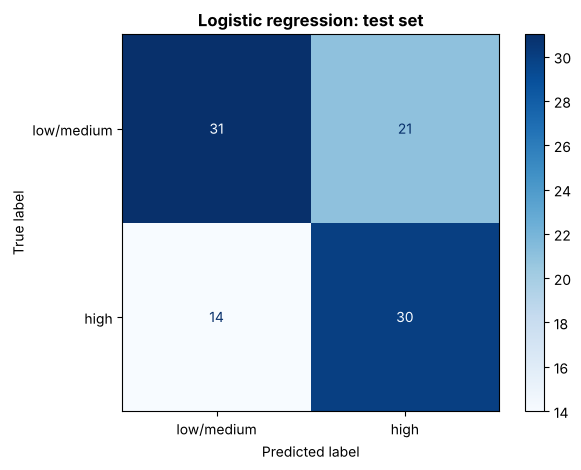

In [18]:
# more detail
    # precision = of the people it called "high", how many really were
    # recall = of the people who really were "high", how many it found
print(classification_report(y_test, pred, target_names=["low/medium", "high"]))

# confusion matrix: rows = real group, columns = predicted group. the diagonal = correct
ConfusionMatrixDisplay.from_estimator(log_reg, X_test, y_test, display_labels=["low/medium", "high"], cmap="Blues")
plt.title("Logistic regression: test set", weight="bold")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()

## 6. Which habits matter most?

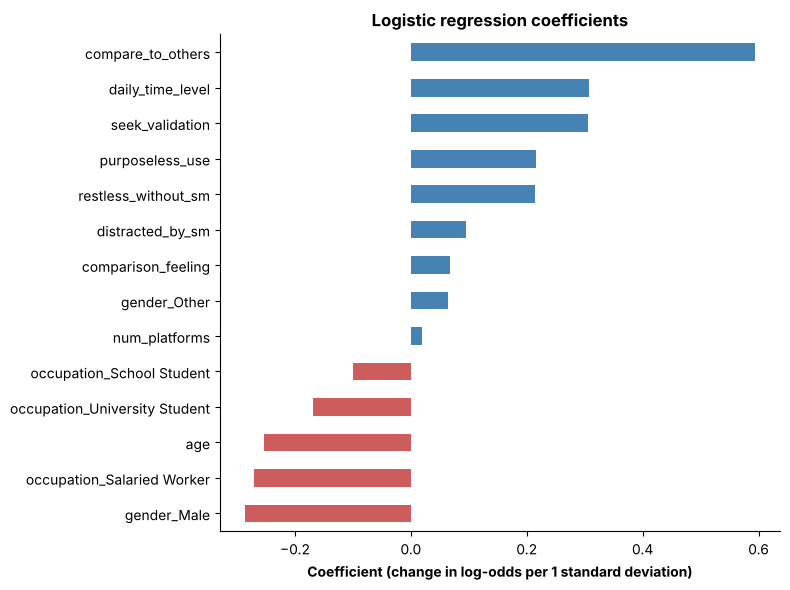

In [19]:
# logistic regression coefficients: one number per input
    # positive (blue) = higher value --> more likely to be "high depression"
    # negative (red) = less likely
    # inputs were scaled, so a bigger bar = a stronger effect
coefs = pd.Series(log_reg[-1].coef_[0], index=X.columns).sort_values()   # log_reg[-1] = the model step of the pipeline

fig, ax = plt.subplots(figsize=(8, 6))
coefs.plot(kind="barh", ax=ax, color=["indianred" if c < 0 else "steelblue" for c in coefs])
ax.set_title("Logistic regression coefficients", weight="bold")
ax.set_xlabel("Coefficient (change in log-odds per 1 standard deviation)", weight="bold")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("figures/lr_coefficients.png", dpi=150)
plt.show()

## 7. Findings

1. **More time on social media goes together with feeling worse, but only moderately.** The average depression score
   goes from 2.0 (less than 1 hour a day) to 3.8 (more than 5 hours a day). The Spearman correlation is 0.31 for depression,
   about 0.3 for worries and concentration, and weaker for sleep (0.17).
2. **How people use social media matters more than how long.** Comparing yourself to others (0.40) and getting distracted
   by social media (0.36) are more strongly related to depression than daily time (0.31).
3. **Social media habits can predict who feels depressed often, better than guessing but far from perfect.**
   With cross-validation, logistic regression got a ROC AUC of 0.76 (accuracy 68%), vs 0.50 (accuracy 54%) for the baseline.
   On the test set it got 0.70 (accuracy 64%). The test set is only 96 people, so a small difference from cross-validation is normal.
4. **Comparing yourself to others has by far the biggest coefficient** (0.59), about twice daily time (0.31) and seeking validation (0.31).
   Being older or male was linked to a lower chance of being in the "high" group.

## Limitations
- **Correlation, not causation.** People who already feel down might spend more time on social media, not the other way around.
- **Who answered.** ~480 people from an online form, mostly university students in their early 20s. The results don't apply to e.g. Canadian teenagers.
- **One self-reported question.** "How often do you feel depressed?" on a 1-5 scale is not a medical diagnosis.
- **Small data.** ~380 people to train on and 96 to test on, so the scores could move a fair bit with different people.
- **My cut-off.** Calling 4-5 "high" was my choice. A different cut-off would change the numbers.

## Possible next steps
1. Predict the full 1-5 score instead of just high / not high.
2. Try other models (e.g. decision trees or a random forest) and see if they do better than logistic regression.